# 04 · Can our intervals be trusted? Coverage simulation

**Track 2 · Action item F2 · Grading criterion 4 (Estimation and uncertainty, 15 marks)**

A 95% confidence interval is a *procedure*: across many repeated samples, about 95% of the intervals it builds should contain the true value. We can't check that on our one real sample, so we check it by simulation:

1. Choose a "true" population whose parameter we know, built to look like our data.
2. Draw a sample of the same size as in our analysis.
3. Build the interval exactly as we do in the report.
4. Record whether it contains the true value.
5. Repeat many times. The share of hits is the actual coverage. It should be close to 95%.

We test the interval methods we actually use, in the situations where they are most likely to fail: skewed, two-peaked glucose in the small stroke group (n = 249), and rare proportions.

Background: [knowledge_base/01_confidence_intervals_and_bootstrap.md](../knowledge_base/01_confidence_intervals_and_bootstrap.md)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.mixture import GaussianMixture
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep

from src.config import SEED, N_SIM, ALPHA, FIGURES, TABLES
from src.data import load_raw

rng = np.random.default_rng(SEED)
B_INNER = 1_000  # bootstrap resamples inside each simulated dataset (10,000 in the real analysis)
df = load_raw()
print(f"seed = {SEED}, simulated datasets per scenario = {N_SIM}, inner bootstrap = {B_INNER}")

seed = 42, simulated datasets per scenario = 1000, inner bootstrap = 1000


## Scenario A · Mean glucose (skewed, two peaks)

"Truth" = the 2-component log-normal mixture fitted in [03_distribution_glucose](03_distribution_glucose.ipynb), whose mean we can compute exactly: Σ wⱼ · exp(μⱼ + σⱼ²/2). We use two versions:

- **Stroke patients, n = 249.** Mixture refitted to the 249 stroke patients only. This group has more high-glucose patients, so it is the most skewed, smallest case.
- **All patients, n = 5,110.** Mixture fitted to everyone.

Methods: the t-interval (assumes the sample mean is approximately Normal) and the percentile bootstrap.

In [2]:
def fit_mixture(v):
    gm = GaussianMixture(2, n_init=10, random_state=SEED).fit(np.log(v).reshape(-1, 1))
    return gm.weights_, gm.means_.ravel(), np.sqrt(gm.covariances_.ravel())

def mixture_mean(p):
    w, mu, sd = p
    return float(np.sum(w * np.exp(mu + sd**2 / 2)))

def sample_mixture(p, size, rng):
    w, mu, sd = p
    comp = rng.choice(len(w), size=size, p=w)
    return np.exp(rng.normal(mu[comp], sd[comp]))

def coverage_mean(p, n, label):
    truth = mixture_mean(p)
    hits = {"t-interval": [], "percentile bootstrap": []}
    widths = {k: [] for k in hits}
    tq = stats.t.ppf(1 - ALPHA / 2, n - 1)
    for _ in range(N_SIM):
        s = sample_mixture(p, n, rng)
        m, se = s.mean(), s.std(ddof=1) / np.sqrt(n)
        lo, hi = m - tq * se, m + tq * se
        hits["t-interval"].append(lo <= truth <= hi); widths["t-interval"].append(hi - lo)
        boots = s[rng.integers(0, n, size=(B_INNER, n))].mean(axis=1)
        lo, hi = np.quantile(boots, [ALPHA / 2, 1 - ALPHA / 2])
        hits["percentile bootstrap"].append(lo <= truth <= hi); widths["percentile bootstrap"].append(hi - lo)
    return [{"scenario": label, "method": k, "true_value": truth,
             "hits": int(np.sum(v)), "mean_width": np.mean(widths[k])} for k, v in hits.items()]

g = df["avg_glucose_level"].to_numpy()
p_stroke = fit_mixture(g[df["stroke"] == 1])
p_all = fit_mixture(g)
rows = []
rows += coverage_mean(p_stroke, 249, "Mean glucose, stroke group (n=249)")
rows += coverage_mean(p_all, 5110, "Mean glucose, all patients (n=5,110)")
pd.DataFrame(rows)

,scenario,method,true_value,hits,mean_width
0,"Mean glucose, stroke group (n=249)",t-interval,132.524025,960,15.433931
1,"Mean glucose, stroke group (n=249)",percentile bootstrap,132.524025,955,15.220749
2,"Mean glucose, all patients (n=5,110)",t-interval,106.122333,957,2.477469
3,"Mean glucose, all patients (n=5,110)",percentile bootstrap,106.122333,958,2.466473


## Scenario B · Stroke rates (rare events)

The report gives many stroke rates for subgroups. "Truth" = a binomial with the observed rate and group size. We compare the textbook Wald interval p̂ ± 1.96·SE with the Wilson interval used in `src/stats_utils.py`.

| Situation | True rate | n |
|---|---|---|
| Missing-BMI patients | 40/201 = 19.9% | 201 |
| Whole sample (base rate) | 249/5,110 = 4.87% | 5,110 |
| Under-18s | 2/856 = 0.23% | 856 |

In [3]:
def coverage_prop(p, n, label):
    counts = rng.binomial(n, p, size=N_SIM)
    out = []
    for method, name in [("normal", "Wald"), ("wilson", "Wilson")]:
        lo, hi = proportion_confint(counts, n, alpha=ALPHA, method=method)
        out.append({"scenario": label, "method": name, "true_value": p,
                    "hits": int(np.sum((lo <= p) & (p <= hi))), "mean_width": np.mean(hi - lo)})
    return out

rows += coverage_prop(40 / 201, 201, "Stroke rate, missing BMI (n=201)")
rows += coverage_prop(249 / 5110, 5110, "Stroke rate, all (n=5,110)")
rows += coverage_prop(2 / 856, 856, "Stroke rate, under-18 (n=856)")

## Scenario C · Difference in stroke rates (missing vs recorded BMI)

The headline missing-BMI comparison is 19.9% vs 4.3%. We check Newcombe's interval for the difference, used in `risk_difference()`, against the Wald interval.

In [4]:
def coverage_diff(p1, n1, p2, n2, label):
    truth = p1 - p2
    c1 = rng.binomial(n1, p1, size=N_SIM); c2 = rng.binomial(n2, p2, size=N_SIM)
    out = []
    for method, name in [("wald", "Wald"), ("newcomb", "Newcombe")]:
        hits, widths = [], []
        for a, b in zip(c1, c2):
            lo, hi = confint_proportions_2indep(a, n1, b, n2, method=method, compare="diff", alpha=ALPHA)
            hits.append(lo <= truth <= hi); widths.append(hi - lo)
        out.append({"scenario": label, "method": name, "true_value": truth,
                    "hits": int(np.sum(hits)), "mean_width": np.mean(widths)})
    return out

rows += coverage_diff(40 / 201, 201, 209 / 4909, 4909, "Risk difference, BMI missing vs recorded")

## Results

Coverage is itself estimated from N_SIM simulations, so it has Monte Carlo error. We show a Wilson 95% interval for each coverage. With 1,000 simulations, a correct method lands between about 93.6% and 96.4%.

In [5]:
res = pd.DataFrame(rows)
res["coverage"] = res["hits"] / N_SIM
ci = [proportion_confint(h, N_SIM, alpha=0.05, method="wilson") for h in res["hits"]]
res["coverage_lo"] = [c[0] for c in ci]
res["coverage_hi"] = [c[1] for c in ci]
res["n_sim"] = N_SIM
res.to_csv(TABLES / "coverage_simulation.csv", index=False)
res[["scenario", "method", "coverage", "coverage_lo", "coverage_hi", "mean_width"]].round(4)

,scenario,method,coverage,coverage_lo,coverage_hi,mean_width
0,"Mean glucose, stroke group (n=249)",t-interval,0.960,0.9460,0.9705,15.4339
1,"Mean glucose, stroke group (n=249)",percentile bootstrap,0.955,0.9403,0.9662,15.2207
2,"Mean glucose, all patients (n=5,110)",t-interval,0.957,0.9426,0.9679,2.4775
3,"Mean glucose, all patients (n=5,110)",percentile bootstrap,0.958,0.9437,0.9688,2.4665
4,"Stroke rate, missing BMI (n=201)",Wald,0.929,0.9114,0.9433,0.1099
5,"Stroke rate, missing BMI (n=201)",Wilson,0.952,0.9369,0.9636,0.1095
6,"Stroke rate, all (n=5,110)",Wald,0.951,0.9358,0.9627,0.0118
7,"Stroke rate, all (n=5,110)",Wilson,0.960,0.9460,0.9705,0.0118
8,"Stroke rate, under-18 (n=856)",Wald,0.856,0.8329,0.8764,0.0051
9,"Stroke rate, under-18 (n=856)",Wilson,0.959,0.9449,0.9696,0.0076


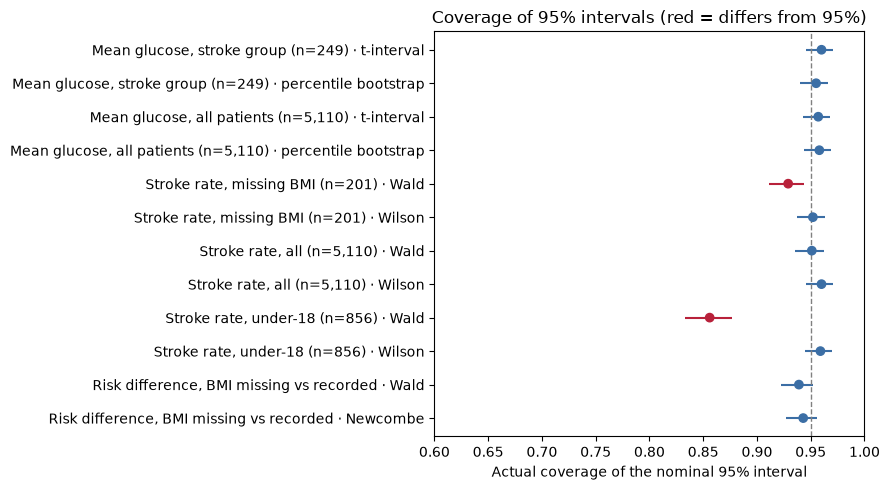

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = res["scenario"] + " · " + res["method"]
ypos = np.arange(len(res))[::-1]
colors = np.where((res["coverage_hi"] >= 0.95) & (res["coverage_lo"] <= 0.95), "#3b6ea5", "#b8213a")
ax.errorbar(res["coverage"], ypos,
            xerr=[res["coverage"] - res["coverage_lo"], res["coverage_hi"] - res["coverage"]],
            fmt="none", ecolor=colors, elinewidth=1.5)
ax.scatter(res["coverage"], ypos, c=colors, zorder=3)
ax.axvline(0.95, color="grey", ls="--", lw=1)
ax.set_yticks(ypos, labels)
ax.set(xlabel="Actual coverage of the nominal 95% interval", xlim=(min(0.6, res["coverage_lo"].min() - 0.02), 1.0),
       title="Coverage of 95% intervals (red = differs from 95%)")
plt.tight_layout()
plt.savefig(FIGURES / "coverage_simulation.png", dpi=150)
plt.show()

## Interpretation

*(Written after running with seed 42 and 1,000 simulations per scenario. If either changes, re-check these numbers against the table above.)*

**The methods we use in the report hold their 95% coverage in every scenario tested.**

| Quantity | Method used in the report | Actual coverage | Verdict |
|---|---|---|---|
| Mean glucose, stroke group (n = 249) | Percentile bootstrap | 95.5% | OK. The t-interval (96.0%) also works: n = 249 is enough for the CLT despite the two peaks. |
| Mean glucose, all (n = 5,110) | Percentile bootstrap | 95.8% | OK |
| Stroke rate, missing BMI (n = 201) | Wilson | 95.2% | OK. **Wald undercovers: 92.9%.** |
| Stroke rate, all (n = 5,110) | Wilson | 96.0% | OK (Wald 95.1% also fine with this many events) |
| Stroke rate, under-18s (n = 856, 2 strokes) | Wilson | 95.9% | OK. **Wald fails badly: 85.6%.** |
| Risk difference, BMI missing vs recorded | Newcombe | 94.3% | OK (Wald 93.9%) |

**What this means**
1. **Use Wilson (or Newcombe for differences) for every stroke rate in the report, never Wald.** With rare events or small groups, the Wald interval misses the truth far more often than it claims: for the under-18s, about 1 time in 7 instead of 1 in 20. The helpers in `src/stats_utils.py` already use Wilson and Newcombe.
2. **The two-peaked shape of glucose does not break intervals for the mean**, even in the 249 stroke patients. The distribution problem found in notebook 03 affects how we *summarise* glucose (the mean hides the two groups), not whether the interval for the mean can be trusted.
3. **How to say it in the report:** "Across 1,000 simulated datasets that mimic ours, 95.5% of bootstrap intervals for the stroke group's mean glucose contained the true mean." Not: "there is a 95% probability the true mean lies in our interval."

**Limits of this check:** the inner bootstrap used 1,000 resamples (the real analysis uses 10,000), and we have not yet checked intervals for odds ratios or the threshold. Those depend on Track 3's model, and can be added with the same approach once it exists.